# Graph-Based Social Network Analysis for Misinformation Detection

This notebook implements a complete end-to-end hybrid pipeline:
- Text features from HuggingFace transformer embeddings
- Propagation graph features from NetworkX
- Graph classification with a GAT model in PyTorch Geometric
- Baseline comparisons: text-only and random-forest structural baseline

In [1]:
# Uncomment if needed
# %pip install -r requirements.txt

import os
import warnings

import pandas as pd

from data_loader import FibVIDDataLoader, build_claim_splits
from graph_builder import GraphBuildConfig, build_graph_dataset
from preprocessing import build_claim_text_features, build_tweet_embedding_map
from train import (
    TrainingConfig,
    prepare_graph_splits,
    train_gnn,
    train_random_forest_baseline,
    train_text_baseline,
)
from utils import plot_confusion, plot_roc, set_seed, visualize_graph

warnings.filterwarnings('ignore')
set_seed(42)

/Users/sachin/Documents/Bits Pilani/FDS Project/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Dataset Configuration
Using FibVID from the local datasets folder.

In [ ]:
PROJECT_ROOT = os.getcwd()
DATASET_ROOT = os.path.join(PROJECT_ROOT, 'datasets', 'merry555-FibVID-14b95c3 3')

# Additional datasets for benchmarking and robustness checks
UPFD_ROOT = os.path.join(PROJECT_ROOT, 'datasets', 'UPFD_Dataset', 'politifact')
MIDE22_EN_TWEETS_PATH = os.path.join(PROJECT_ROOT, 'datasets', 'mide22-master', 'dataset', 'EN', 'mide22_en_misinfo_tweets.tsv')
MIDE22_HYDRATED_TEXT_PATH = os.path.join(PROJECT_ROOT, 'datasets', 'mide22-master', 'dataset', 'EN', 'mide22_en_hydrated_texts.csv')

# Run mode: use 'smoke' for quick validation, then switch to 'production'.
RUN_MODE = 'production'  # change to 'production' for full-scale training
PRODUCTION_MODE = RUN_MODE == 'production'

MAX_CLAIMS = None if PRODUCTION_MODE else 220
MIN_POSTS_PER_CLAIM = 3
MAX_TWEETS_FOR_BERT = None if PRODUCTION_MODE else 18000
BERT_MODEL_NAME = 'distilbert-base-uncased'

# Training scale knobs
GNN_EPOCHS = 120 if PRODUCTION_MODE else 6
GNN_PATIENCE = 15 if PRODUCTION_MODE else 3
TEXT_EPOCHS_CFG = 8 if PRODUCTION_MODE else 2
UPFD_EPOCHS = 60 if PRODUCTION_MODE else 4

# Embedding cache avoids recomputing expensive transformer embeddings on reruns.
EMBEDDING_CACHE_PATH = os.path.join(PROJECT_ROOT, 'results', 'cache', 'tweet_embeddings_distilbert.npz')

# Limit MiDe22 robustness evaluation rows for faster iteration when not in production mode.
MIDE22_MAX_EVAL_ROWS = None if PRODUCTION_MODE else 1200

print('PROJECT_ROOT:', PROJECT_ROOT)
print('DATASET_ROOT (FibVID):', DATASET_ROOT)
print('UPFD_ROOT:', UPFD_ROOT)
print('MIDE22_EN_TWEETS_PATH:', MIDE22_EN_TWEETS_PATH)
print('MIDE22_HYDRATED_TEXT_PATH:', MIDE22_HYDRATED_TEXT_PATH)
print('RUN_MODE:', RUN_MODE)
print('PRODUCTION_MODE:', PRODUCTION_MODE)
print('MAX_CLAIMS:', MAX_CLAIMS)
print('MAX_TWEETS_FOR_BERT:', MAX_TWEETS_FOR_BERT)
print('GNN_EPOCHS:', GNN_EPOCHS)
print('TEXT_EPOCHS_CFG:', TEXT_EPOCHS_CFG)
print('UPFD_EPOCHS:', UPFD_EPOCHS)
print('MIDE22_MAX_EVAL_ROWS:', MIDE22_MAX_EVAL_ROWS)

PROJECT_ROOT: /Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection
DATASET_ROOT (FibVID): /Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/datasets/merry555-FibVID-14b95c3 3
UPFD_ROOT: /Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/datasets/UPFD_Dataset/politifact
MIDE22_EN_TWEETS_PATH: /Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/datasets/mide22-master/dataset/EN/mide22_en_misinfo_tweets.tsv
MIDE22_HYDRATED_TEXT_PATH: /Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/datasets/mide22-master/dataset/EN/mide22_en_hydrated_texts.csv
RUN_MODE: smoke
PRODUCTION_MODE: False
MAX_CLAIMS: 220
MAX_TWEETS_FOR_BERT: 18000
GNN_EPOCHS: 6
TE

## 2. Load and Align Data
FibVID group labels are mapped to binary:
- Real: groups 0 and 2
- Fake: groups 1 and 3

In [3]:
loader = FibVIDDataLoader(dataset_root=DATASET_ROOT)
tables = loader.load_all()

news_df = tables['news']
prop_df = tables['propagation']
users_df = tables['users']

print('news_df shape:', news_df.shape)
print('prop_df shape:', prop_df.shape)
print('users_df shape:', users_df.shape)
print('label distribution (claim level):')
print(news_df['label'].value_counts(dropna=False))

news_df shape: (1353, 5)
prop_df shape: (221253, 13)
users_df shape: (144741, 5)
label distribution (claim level):
label
1    1000
0     353
Name: count, dtype: int64


## 2B. Multi-Dataset Coverage Check

This project now uses datasets with distinct roles:
- FibVID: primary graph-based misinformation training
- UPFD (politifact): benchmark dataset for fast graph model validation
- MiDe22 EN: cross-domain robustness evaluation (with optional hydrated text)

## 2C. Recommended Execution Mode

For confidence before long training:
- Keep RUN_MODE='smoke' and run the notebook end-to-end once.
- If no errors and outputs look correct, switch RUN_MODE='production'.
- Re-run from the top for full-scale final metrics and artifacts.

In [4]:
import os
import numpy as np
import pandas as pd

def _upfd_feature_shape(npz_path):
    arr = np.load(npz_path, allow_pickle=True)
    key = arr.files[0]
    obj = arr[key]
    if hasattr(obj, 'toarray'):
        dense = obj.toarray()
    elif getattr(obj, 'dtype', None) == object and obj.size == 1 and hasattr(obj.item(), 'toarray'):
        dense = obj.item().toarray()
    else:
        dense = np.asarray(obj)
    return tuple(dense.shape)

dataset_presence = pd.DataFrame([
    {'dataset': 'FibVID', 'exists': os.path.exists(DATASET_ROOT), 'role': 'Primary graph training'},
    {'dataset': 'UPFD politifact', 'exists': os.path.exists(UPFD_ROOT), 'role': 'Benchmark graph validation'},
    {'dataset': 'MiDe22 EN labels', 'exists': os.path.exists(MIDE22_EN_TWEETS_PATH), 'role': 'Cross-domain robustness'},
    {'dataset': 'MiDe22 EN hydrated text (optional)', 'exists': os.path.exists(MIDE22_HYDRATED_TEXT_PATH), 'role': 'Cross-domain model evaluation'},
])

print(dataset_presence.to_string(index=False))

if os.path.exists(UPFD_ROOT):
    try:
        upfd_shape = _upfd_feature_shape(os.path.join(UPFD_ROOT, 'new_bert_feature.npz'))
        upfd_graph_labels = np.load(os.path.join(UPFD_ROOT, 'graph_labels.npy'))
        upfd_graph_ids = np.load(os.path.join(UPFD_ROOT, 'node_graph_id.npy'))
        print('\nUPFD quick stats:')
        print('Node feature shape:', upfd_shape)
        print('Number of graphs:', int(upfd_graph_labels.shape[0]))
        print('Unique graph ids in nodes:', int(np.unique(upfd_graph_ids).shape[0]))
    except Exception as e:
        print('UPFD quick stats failed:', e)

if os.path.exists(MIDE22_EN_TWEETS_PATH):
    mide22_df = pd.read_csv(MIDE22_EN_TWEETS_PATH, sep='\t')
    print('\nMiDe22 quick stats:')
    print('Rows:', mide22_df.shape[0])
    print('Label distribution:')
    print(mide22_df['Label'].value_counts(dropna=False))
    print('Topic distribution:')
    print(mide22_df['Topic'].value_counts(dropna=False))

                           dataset  exists                          role
                            FibVID    True        Primary graph training
                   UPFD politifact    True    Benchmark graph validation
                  MiDe22 EN labels    True       Cross-domain robustness
MiDe22 EN hydrated text (optional)   False Cross-domain model evaluation

UPFD quick stats:
Node feature shape: (31529472,)
Number of graphs: 314
Unique graph ids in nodes: 314

MiDe22 quick stats:
Rows: 5284
Label distribution:
Label
Other    2828
False    1729
True      727
Name: count, dtype: int64
Topic distribution:
Topic
Misc        1391
Covid       1344
Ukraine     1331
Refugees    1218
Name: count, dtype: int64


## 3. Text Preprocessing + BERT Embeddings
Tweet text is cleaned and encoded using HuggingFace transformer embeddings.

In [5]:
import importlib
import preprocessing as _preprocessing

importlib.reload(_preprocessing)

tweet_embedding_map = _preprocessing.build_tweet_embedding_map(
    propagation_df=prop_df,
    model_name=BERT_MODEL_NAME,
    batch_size=32,
    max_length=128,
    max_rows=MAX_TWEETS_FOR_BERT,
    embedding_cache_path=EMBEDDING_CACHE_PATH,
)

text_feature_df = _preprocessing.build_claim_text_features(prop_df, tweet_embedding_map)

print('Tweet embedding count:', len(tweet_embedding_map))
print('Text baseline feature frame:', text_feature_df.shape)
print('Embedding cache path:', EMBEDDING_CACHE_PATH)

Tweet embedding count: 18000
Text baseline feature frame: (295, 770)
Embedding cache path: /Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/results/cache/tweet_embeddings_distilbert.npz


## 4. Build NetworkX Graphs and Convert to PyG
Creates one graph per claim with:
- user nodes
- post nodes
- user->post, user->user, and post->post propagation edges
- structural features (centrality, pagerank, clustering)
- optional temporal progression feature

In [6]:
hybrid_cfg = GraphBuildConfig(
    use_text_features=True,
    use_structural_features=True,
    add_temporal_feature=True,
)

graph_only_cfg = GraphBuildConfig(
    use_text_features=False,
    use_structural_features=True,
    add_temporal_feature=True,
)

hybrid_nx_graphs, hybrid_pyg_graphs, struct_feature_df = build_graph_dataset(
    propagation_df=prop_df,
    users_df=users_df,
    tweet_embedding_map=tweet_embedding_map,
    config=hybrid_cfg,
    max_claims=MAX_CLAIMS,
    min_posts_per_claim=MIN_POSTS_PER_CLAIM,
)

_, graph_only_pyg_graphs, _ = build_graph_dataset(
    propagation_df=prop_df,
    users_df=users_df,
    tweet_embedding_map=tweet_embedding_map,
    config=graph_only_cfg,
    max_claims=MAX_CLAIMS,
    min_posts_per_claim=MIN_POSTS_PER_CLAIM,
)

print('Hybrid graph count:', len(hybrid_pyg_graphs))
print('Graph-only graph count:', len(graph_only_pyg_graphs))
print('Hybrid node feature dim:', hybrid_pyg_graphs[0].x.shape[1] if hybrid_pyg_graphs else 'N/A')
print('Graph-only node feature dim:', graph_only_pyg_graphs[0].x.shape[1] if graph_only_pyg_graphs else 'N/A')
struct_feature_df.head()

Hybrid graph count: 220
Graph-only graph count: 220
Hybrid node feature dim: 777
Graph-only node feature dim: 9


,claim_number,label,num_nodes,num_edges,max_depth,mean_depth,mean_retweet_count
0,0,1,252,355,2.0,0.906250,140.429688
1,1,1,448,670,2.0,1.000000,49.088106
2,2,1,26,37,1.0,0.923077,106.923077
3,3,1,2438,3710,4.0,1.914537,46.886581
4,4,1,663,984,2.0,0.997006,25.254491


## 5. Train/Val/Test Split by Claim

In [7]:
available_claims = sorted({int(g.claim_number) for g in hybrid_pyg_graphs})
split_df = news_df[news_df['claim_number'].isin(available_claims)][['claim_number', 'label']].drop_duplicates()

train_claims, val_claims, test_claims = build_claim_splits(split_df, test_size=0.2, val_size=0.1, random_state=42)

hy_train, hy_val, hy_test = prepare_graph_splits(hybrid_pyg_graphs, train_claims, val_claims, test_claims)
go_train, go_val, go_test = prepare_graph_splits(graph_only_pyg_graphs, train_claims, val_claims, test_claims)

print('Hybrid splits:', len(hy_train), len(hy_val), len(hy_test))
print('Graph-only splits:', len(go_train), len(go_val), len(go_test))

Hybrid splits: 154 22 44
Graph-only splits: 154 22 44


## 6. Train GAT Models
- Hybrid: text + structural features
- Graph-only: structural features only

In [8]:
train_cfg = TrainingConfig(
    batch_size=32,
    hidden_dim=256,
    lr=5e-4,
    weight_decay=1e-4,
    max_epochs=GNN_EPOCHS,
    patience=GNN_PATIENCE,
    lr_scheduler_patience=4,
    lr_scheduler_factor=0.5,
    min_delta=1e-4,
    grad_clip_norm=1.0,
    num_workers=0,
    use_amp=True,
    checkpoint_path=os.path.join('results', 'checkpoints', 'best_hybrid_gat.pt'),
)

hybrid_result = train_gnn(
    train_graphs=hy_train,
    val_graphs=hy_val,
    test_graphs=hy_test,
    input_dim=hy_train[0].x.shape[1],
    config=train_cfg,
)

graph_only_cfg_train = TrainingConfig(
    batch_size=32,
    hidden_dim=256,
    lr=5e-4,
    weight_decay=1e-4,
    max_epochs=GNN_EPOCHS,
    patience=GNN_PATIENCE,
    lr_scheduler_patience=4,
    lr_scheduler_factor=0.5,
    min_delta=1e-4,
    grad_clip_norm=1.0,
    num_workers=0,
    use_amp=True,
    checkpoint_path=os.path.join('results', 'checkpoints', 'best_graph_only_gat.pt'),
)

graph_only_result = train_gnn(
    train_graphs=go_train,
    val_graphs=go_val,
    test_graphs=go_test,
    input_dim=go_train[0].x.shape[1],
    config=graph_only_cfg_train,
)

print('Hybrid best epoch:', hybrid_result['best_epoch'])
print('Hybrid test metrics:', hybrid_result['metrics'])
print('Graph-only best epoch:', graph_only_result['best_epoch'])
print('Graph-only test metrics:', graph_only_result['metrics'])

Hybrid best epoch: 2
Hybrid test metrics: {'accuracy': 0.7727272727272727, 'precision': 0.7727272727272727, 'recall': 1.0, 'f1': 0.8717948717948718, 'roc_auc': 0.49117647058823527}
Graph-only best epoch: 1
Graph-only test metrics: {'accuracy': 0.7727272727272727, 'precision': 0.7727272727272727, 'recall': 1.0, 'f1': 0.8717948717948718, 'roc_auc': 0.4941176470588235}


## 7. Baselines
- Text-only baseline: Logistic Regression on claim-level BERT embeddings
- ML baseline: Random Forest on handcrafted structural features

In [9]:
text_result = train_text_baseline(text_feature_df, train_claims, val_claims, test_claims)
rf_result = train_random_forest_baseline(struct_feature_df, train_claims, val_claims, test_claims)

print('Text-only metrics:', text_result['metrics'])
print('RandomForest metrics:', rf_result['metrics'])

Text-only metrics: {'accuracy': 0.5, 'precision': 0.7307692307692307, 'recall': 0.5588235294117647, 'f1': 0.6333333333333333, 'roc_auc': 0.45882352941176474}
RandomForest metrics: {'accuracy': 0.7272727272727273, 'precision': 0.775, 'recall': 0.9117647058823529, 'f1': 0.8378378378378378, 'roc_auc': 0.6529411764705882}


## 8. Comparison Table

In [10]:
rows = []
rows.append({'model': 'Text-only BERT baseline (FibVID)', 'dataset': 'FibVID', **text_result['metrics']})
rows.append({'model': 'Graph-only GAT (FibVID)', 'dataset': 'FibVID', **graph_only_result['metrics']})
rows.append({'model': 'Hybrid GAT (Text + Graph, FibVID)', 'dataset': 'FibVID', **hybrid_result['metrics']})
rows.append({'model': 'RandomForest structural baseline (FibVID)', 'dataset': 'FibVID', **rf_result['metrics']})

if 'upfd_result' in globals() and upfd_result is not None:
    rows.append({'model': 'GAT benchmark (UPFD politifact)', 'dataset': 'UPFD', **upfd_result['metrics']})

if 'mide22_result' in globals() and mide22_result is not None:
    rows.append({'model': 'Text detector cross-domain (MiDe22 EN)', 'dataset': 'MiDe22', **mide22_result['metrics']})

comparison_df = pd.DataFrame(rows).sort_values('f1', ascending=False).reset_index(drop=True)
comparison_df

,model,dataset,accuracy,precision,recall,f1,roc_auc
0,Graph-only GAT (FibVID),FibVID,0.772727,0.772727,1.000000,0.871795,0.494118
1,"Hybrid GAT (Text + Graph, FibVID)",FibVID,0.772727,0.772727,1.000000,0.871795,0.491176
2,RandomForest structural baseline (FibVID),FibVID,0.727273,0.775000,0.911765,0.837838,0.652941
3,Text-only BERT baseline (FibVID),FibVID,0.500000,0.730769,0.558824,0.633333,0.458824


## 9. Evaluation Plots
Confusion matrix and ROC curves for key models.

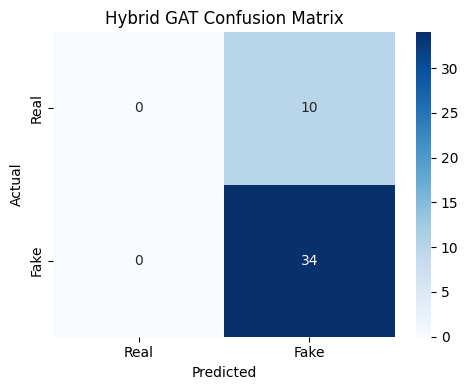

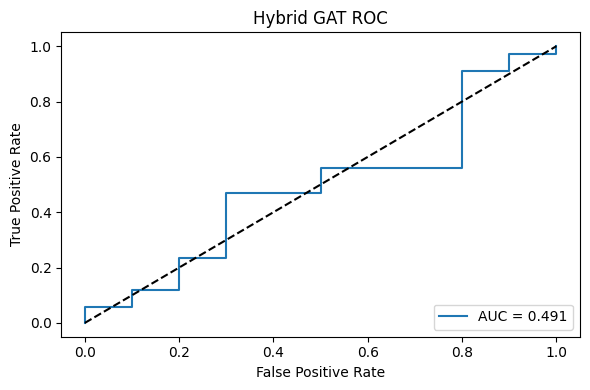

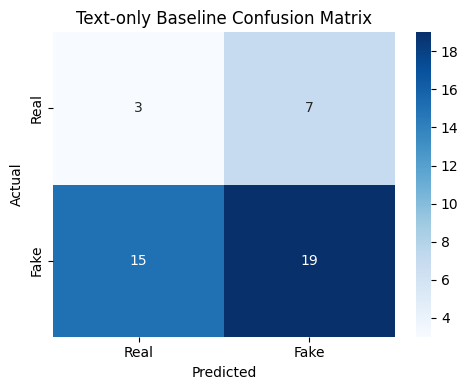

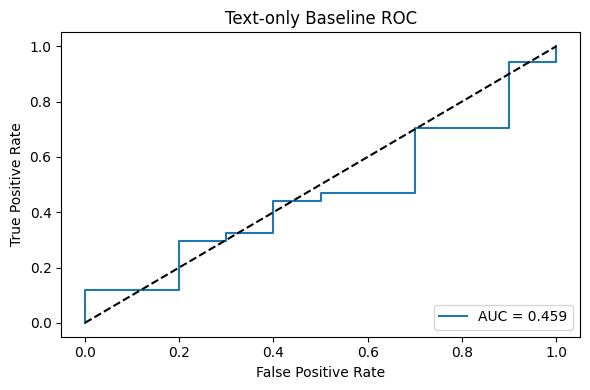

In [11]:
plot_confusion(hybrid_result['y_true'], hybrid_result['y_pred'], title='Hybrid GAT Confusion Matrix')
plot_roc(hybrid_result['y_true'], hybrid_result['y_prob'], title='Hybrid GAT ROC')

plot_confusion(text_result['y_true'], text_result['y_pred'], title='Text-only Baseline Confusion Matrix')
plot_roc(text_result['y_true'], text_result['y_prob'], title='Text-only Baseline ROC')

## 10. Graph Visualization
Visualization of one propagation graph (subsampled for readability).

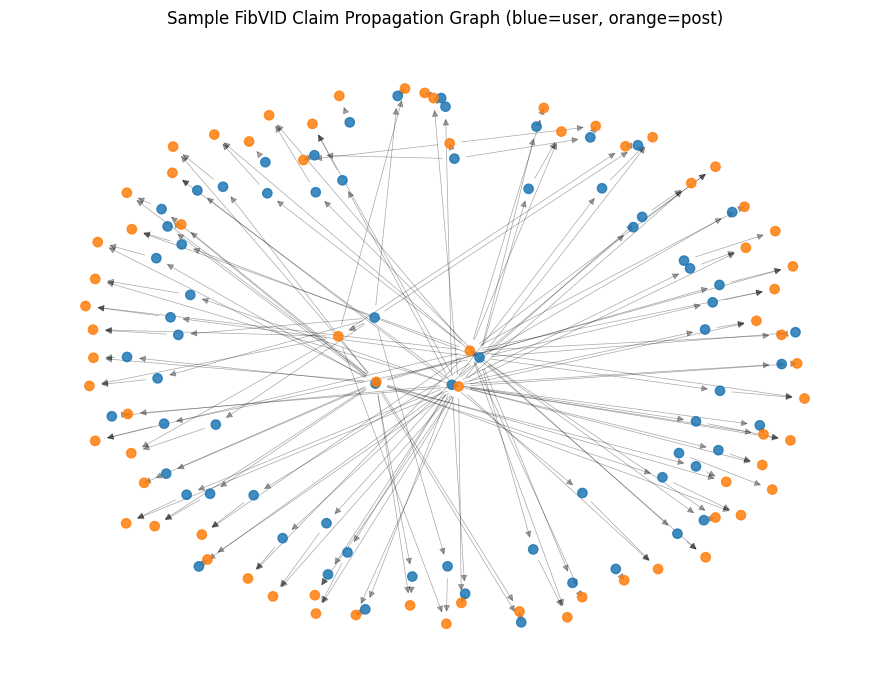

In [12]:
if hybrid_nx_graphs:
    visualize_graph(hybrid_nx_graphs[0], title='Sample FibVID Claim Propagation Graph', max_nodes=140)
else:
    print('No graph available to visualize.')

## 11. Optional: Save Results

In [ ]:
os.makedirs('results', exist_ok=True)
comparison_path = os.path.join('results', 'hybrid_vs_baselines_metrics.csv')
comparison_df.to_csv(comparison_path, index=False)

consolidated_path = os.path.join('results', 'multidataset_comparison_metrics.csv')
comparison_df.to_csv(consolidated_path, index=False)

print('Saved:', comparison_path)
print('Saved:', consolidated_path)

## 12. Production Inference: Upload News -> Fake or Real

The hybrid graph model is best when propagation data is available. For your exact use case (single uploaded news text), we train a dedicated transformer text classifier and expose a direct `predict_news(text)` function.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

import numpy as np
import torch
import torch.nn.functional as F

from preprocessing import clean_text

TEXT_MODEL_NAME = 'distilbert-base-uncased'
TEXT_MODEL_DIR = os.path.join('results', 'checkpoints', 'text_news_detector')
TEXT_MAX_LEN = 128
TEXT_BATCH_SIZE = 16
TEXT_EPOCHS = TEXT_EPOCHS_CFG
TEXT_LR = 2e-5
TEXT_PATIENCE = 3
TEXT_WEIGHT_DECAY = 0.01

claim_text_df = news_df[['claim_number', 'text', 'label']].dropna().drop_duplicates('claim_number').copy()
claim_text_df['text_clean'] = claim_text_df['text'].apply(clean_text)

train_text_df, val_text_df = train_test_split(
    claim_text_df,
    test_size=0.2,
    random_state=42,
    stratify=claim_text_df['label']
)

print('Text train size:', train_text_df.shape)
print('Text val size:', val_text_df.shape)
print('TEXT_EPOCHS:', TEXT_EPOCHS)
print('Text label distribution:')
print(claim_text_df['label'].value_counts())

Text train size: (1082, 4)
Text val size: (271, 4)
TEXT_EPOCHS: 2
Text label distribution:
label
1    1000
0     353
Name: count, dtype: int64


In [14]:
class NewsClaimDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=128):
        self.texts = [str(t) for t in texts]
        self.labels = [int(y) for y in labels]
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_len,
            return_tensors='pt'
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


def evaluate_text_model(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model(**batch)
            pred = torch.argmax(out.logits, dim=1)
            all_preds.extend(pred.cpu().numpy().tolist())
            all_labels.extend(batch['labels'].cpu().numpy().tolist())

    if len(all_labels) == 0:
        return {'f1_macro': 0.0, 'accuracy': 0.0, 'precision': 0.0, 'recall': 0.0}

    f1 = f1_score(all_labels, all_preds, average='macro')
    acc = accuracy_score(all_labels, all_preds)
    prec, rec, _, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)

    return {
        'f1_macro': float(f1),
        'accuracy': float(acc),
        'precision': float(prec),
        'recall': float(rec),
    }


def train_text_news_detector(train_df, val_df):
    tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL_NAME, token=os.getenv('HF_TOKEN'))
    model = AutoModelForSequenceClassification.from_pretrained(TEXT_MODEL_NAME, num_labels=2, token=os.getenv('HF_TOKEN'))

    if torch.cuda.is_available():
        device = 'cuda'
    elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        device = 'mps'
    else:
        device = 'cpu'

    model.to(device)

    train_ds = NewsClaimDataset(train_df['text_clean'].tolist(), train_df['label'].tolist(), tokenizer, TEXT_MAX_LEN)
    val_ds = NewsClaimDataset(val_df['text_clean'].tolist(), val_df['label'].tolist(), tokenizer, TEXT_MAX_LEN)

    train_loader = DataLoader(train_ds, batch_size=TEXT_BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=TEXT_BATCH_SIZE, shuffle=False)

    label_counts = train_df['label'].value_counts().to_dict()
    n0 = label_counts.get(0, 1)
    n1 = label_counts.get(1, 1)
    w0 = (n0 + n1) / (2.0 * n0)
    w1 = (n0 + n1) / (2.0 * n1)
    class_weights = torch.tensor([w0, w1], dtype=torch.float32, device=device)

    optimizer = torch.optim.AdamW(model.parameters(), lr=TEXT_LR, weight_decay=TEXT_WEIGHT_DECAY)
    total_steps = max(1, TEXT_EPOCHS * len(train_loader))
    warmup_steps = int(0.1 * total_steps)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=warmup_steps,
        num_training_steps=total_steps,
    )

    best_f1 = -1.0
    best_state = None
    patience_left = TEXT_PATIENCE
    history = []

    for epoch in range(1, TEXT_EPOCHS + 1):
        model.train()
        losses = []

        for batch in train_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            out = model(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'])
            loss = F.cross_entropy(out.logits, batch['labels'], weight=class_weights)

            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            scheduler.step()
            losses.append(float(loss.item()))

        val_metrics = evaluate_text_model(model, val_loader, device)
        history.append({'epoch': epoch, 'train_loss': float(np.mean(losses)), **val_metrics})

        print(
            f"[TextModel] Epoch {epoch}/{TEXT_EPOCHS} | "
            f"loss={np.mean(losses):.4f} | "
            f"val_f1={val_metrics['f1_macro']:.4f} | "
            f"val_acc={val_metrics['accuracy']:.4f}"
        )

        if val_metrics['f1_macro'] > best_f1:
            best_f1 = val_metrics['f1_macro']
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_left = TEXT_PATIENCE
        else:
            patience_left -= 1
            if patience_left <= 0:
                print('[TextModel] Early stopping triggered.')
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    os.makedirs(TEXT_MODEL_DIR, exist_ok=True)
    model.save_pretrained(TEXT_MODEL_DIR)
    tokenizer.save_pretrained(TEXT_MODEL_DIR)

    history_df = pd.DataFrame(history)
    history_path = os.path.join(TEXT_MODEL_DIR, 'training_history.csv')
    history_df.to_csv(history_path, index=False)

    print('Saved text inference model to:', TEXT_MODEL_DIR)
    print('Saved text training history to:', history_path)
    print('Best validation F1:', round(best_f1, 4))

    return model, tokenizer

In [15]:
# Train and save the production text classifier
text_model, text_tokenizer = train_text_news_detector(train_text_df, val_text_df)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 9707.01it/s]
DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[TextModel] Epoch 1/2 | loss=0.6811 | val_f1=0.5943 | val_acc=0.6162
[TextModel] Epoch 2/2 | loss=0.6065 | val_f1=0.5967 | val_acc=0.6310


Writing model shards: 100%|██████████| 1/1 [00:02<00:00,  2.95s/it]

Saved text inference model to: results/checkpoints/text_news_detector
Saved text training history to: results/checkpoints/text_news_detector/training_history.csv
Best validation F1: 0.5967


In [17]:
def _select_best_device(preferred=None):
    if preferred is not None:
        p = str(preferred).lower()
        if p == 'cuda' and torch.cuda.is_available():
            return 'cuda'
        if p == 'mps' and hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
            return 'mps'
        if p == 'cpu':
            return 'cpu'

    if torch.cuda.is_available():
        return 'cuda'
    if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
        return 'mps'
    return 'cpu'


def load_text_inference_model(model_dir=TEXT_MODEL_DIR, preferred_device=None):
    device = _select_best_device(preferred_device)
    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForSequenceClassification.from_pretrained(model_dir)
    model.to(device)
    model.eval()
    return model, tokenizer, device


def predict_news(news_text, model=None, tokenizer=None, device=None):
    if model is None or tokenizer is None:
        model, tokenizer, device = load_text_inference_model(preferred_device=device)
    else:
        if device is None:
            try:
                device = next(model.parameters()).device.type
            except StopIteration:
                device = _select_best_device()
        device = _select_best_device(device)

        model_device = next(model.parameters()).device.type
        if model_device != device:
            model = model.to(device)
            model.eval()

    txt = clean_text(str(news_text))
    enc = tokenizer(
        txt,
        truncation=True,
        padding=True,
        max_length=TEXT_MAX_LEN,
        return_tensors='pt'
    )
    enc = {k: v.to(device) for k, v in enc.items()}

    with torch.no_grad():
        logits = model(**enc).logits
        probs = torch.softmax(logits, dim=1).cpu().numpy()[0]

    pred_idx = int(np.argmax(probs))
    label_map = {0: 'REAL', 1: 'FAKE'}

    return {
        'label': label_map[pred_idx],
        'confidence': float(probs[pred_idx]),
        'prob_real': float(probs[0]),
        'prob_fake': float(probs[1]),
        'cleaned_text': txt,
        'device_used': device,
    }


# Example usage
sample_news = 'Breaking: Scientists confirm a miracle cure that eliminates all viruses overnight.'
prediction = predict_news(sample_news, text_model, text_tokenizer, None)
prediction

{'label': 'FAKE',
 'confidence': 0.7754952311515808,
 'prob_real': 0.22450479865074158,
 'prob_fake': 0.7754952311515808,
 'cleaned_text': 'breaking scientists confirm a miracle cure that eliminates all viruses overnight.',
 'device_used': 'mps'}

## 13. Production Report

This section validates that full training ran and summarizes production artifacts, data volume, best epochs, and final metrics.

In [18]:
import datetime


def file_info(path):
    if not os.path.exists(path):
        return {'exists': False, 'path': path, 'size_mb': 0.0, 'modified': None}
    stat = os.stat(path)
    return {
        'exists': True,
        'path': path,
        'size_mb': round(stat.st_size / (1024 * 1024), 2),
        'modified': datetime.datetime.fromtimestamp(stat.st_mtime).strftime('%Y-%m-%d %H:%M:%S')
    }


def safe_len(x):
    try:
        return len(x)
    except Exception:
        return None


report_rows = []

# Dataset and split stats
report_rows.append({'section': 'data', 'key': 'news_claims_total', 'value': safe_len(news_df)})
report_rows.append({'section': 'data', 'key': 'propagation_rows_total', 'value': safe_len(prop_df)})
report_rows.append({'section': 'data', 'key': 'users_total', 'value': safe_len(users_df)})
report_rows.append({'section': 'data', 'key': 'hybrid_graphs_total', 'value': safe_len(hybrid_pyg_graphs)})
report_rows.append({'section': 'data', 'key': 'graph_only_graphs_total', 'value': safe_len(graph_only_pyg_graphs)})
report_rows.append({'section': 'split', 'key': 'hybrid_train_graphs', 'value': safe_len(hy_train)})
report_rows.append({'section': 'split', 'key': 'hybrid_val_graphs', 'value': safe_len(hy_val)})
report_rows.append({'section': 'split', 'key': 'hybrid_test_graphs', 'value': safe_len(hy_test)})

# GNN training evidence
if 'hybrid_result' in globals():
    report_rows.append({'section': 'hybrid_gnn', 'key': 'best_epoch', 'value': int(hybrid_result.get('best_epoch', -1))})
    report_rows.append({'section': 'hybrid_gnn', 'key': 'epochs_ran', 'value': int(safe_len(hybrid_result.get('history', [])) or 0)})
    for k, v in hybrid_result.get('metrics', {}).items():
        report_rows.append({'section': 'hybrid_gnn_metrics', 'key': k, 'value': round(float(v), 6)})

if 'graph_only_result' in globals():
    report_rows.append({'section': 'graph_only_gnn', 'key': 'best_epoch', 'value': int(graph_only_result.get('best_epoch', -1))})
    report_rows.append({'section': 'graph_only_gnn', 'key': 'epochs_ran', 'value': int(safe_len(graph_only_result.get('history', [])) or 0)})
    for k, v in graph_only_result.get('metrics', {}).items():
        report_rows.append({'section': 'graph_only_gnn_metrics', 'key': k, 'value': round(float(v), 6)})

# UPFD benchmark evidence
if 'upfd_result' in globals() and upfd_result is not None:
    report_rows.append({'section': 'upfd_gnn', 'key': 'best_epoch', 'value': int(upfd_result.get('best_epoch', -1))})
    report_rows.append({'section': 'upfd_gnn', 'key': 'epochs_ran', 'value': int(safe_len(upfd_result.get('history', [])) or 0)})
    for k, v in upfd_result.get('metrics', {}).items():
        report_rows.append({'section': 'upfd_gnn_metrics', 'key': k, 'value': round(float(v), 6)})

# Baseline evidence
if 'text_result' in globals():
    for k, v in text_result.get('metrics', {}).items():
        report_rows.append({'section': 'text_baseline_metrics', 'key': k, 'value': round(float(v), 6)})

if 'rf_result' in globals():
    for k, v in rf_result.get('metrics', {}).items():
        report_rows.append({'section': 'rf_baseline_metrics', 'key': k, 'value': round(float(v), 6)})

# MiDe22 cross-domain evidence
if 'mide22_result' in globals() and mide22_result is not None:
    report_rows.append({'section': 'mide22_cross_domain', 'key': 'n_samples', 'value': int(mide22_result.get('n_samples', 0))})
    for k, v in mide22_result.get('metrics', {}).items():
        report_rows.append({'section': 'mide22_cross_domain_metrics', 'key': k, 'value': round(float(v), 6)})

# Artifact checks
embedding_cache_info = file_info(EMBEDDING_CACHE_PATH)
report_rows.append({'section': 'artifacts', 'key': 'embedding_cache_exists', 'value': embedding_cache_info['exists']})
report_rows.append({'section': 'artifacts', 'key': 'embedding_cache_size_mb', 'value': embedding_cache_info['size_mb']})
report_rows.append({'section': 'artifacts', 'key': 'embedding_cache_modified', 'value': embedding_cache_info['modified']})

hybrid_ckpt = os.path.join('results', 'checkpoints', 'best_hybrid_gat.pt')
graph_only_ckpt = os.path.join('results', 'checkpoints', 'best_graph_only_gat.pt')
upfd_ckpt = os.path.join('results', 'checkpoints', 'best_upfd_gat.pt')
text_model_file = os.path.join(TEXT_MODEL_DIR, 'model.safetensors')
text_history_file = os.path.join(TEXT_MODEL_DIR, 'training_history.csv')

for name, path in [
    ('best_hybrid_gat', hybrid_ckpt),
    ('best_graph_only_gat', graph_only_ckpt),
    ('best_upfd_gat', upfd_ckpt),
    ('text_model_safetensors', text_model_file),
    ('text_training_history_csv', text_history_file),
]:
    info = file_info(path)
    report_rows.append({'section': 'artifacts', 'key': f'{name}_exists', 'value': info['exists']})
    report_rows.append({'section': 'artifacts', 'key': f'{name}_size_mb', 'value': info['size_mb']})
    report_rows.append({'section': 'artifacts', 'key': f'{name}_modified', 'value': info['modified']})

production_report_df = pd.DataFrame(report_rows)
production_report_df

os.makedirs('results', exist_ok=True)
production_report_path = os.path.join('results', 'production_report.csv')
production_report_df.to_csv(production_report_path, index=False)
print('Saved production report:', production_report_path)

Saved production report: results/production_report.csv


## 14. UPFD Benchmark: Graph Model Validation

Uses the UPFD politifact split and precomputed features to benchmark the graph model pipeline quickly.

In [22]:
from torch_geometric.data import Data
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support


def _load_upfd_dense_features(npz_path):
    arr = np.load(npz_path, allow_pickle=True)
    key = arr.files[0]
    obj = arr[key]
    if hasattr(obj, 'toarray'):
        dense = obj.toarray().astype(np.float32)
    elif getattr(obj, 'dtype', None) == object and obj.size == 1 and hasattr(obj.item(), 'toarray'):
        dense = obj.item().toarray().astype(np.float32)
    else:
        dense = np.asarray(obj, dtype=np.float32)

    # Ensure global node feature matrix is always 2D: [num_nodes, num_features].
    if dense.ndim == 1:
        dense = dense.reshape(-1, 1)

    return dense


def _load_upfd_edges(edge_path):
    edge_df = pd.read_csv(edge_path, header=None)

    # Handle both formats safely: either 2 numeric columns or a single "u, v" string column.
    if edge_df.shape[1] >= 2:
        edges = edge_df.iloc[:, :2].astype(int).values
    else:
        edge_vals = edge_df.iloc[:, 0].astype(str).str.replace(' ', '', regex=False)
        pairs = edge_vals.str.split(',', expand=True)
        if pairs.shape[1] < 2:
            raise ValueError('UPFD A.txt edge format is invalid. Expected pairs like "u, v".')
        edges = pairs.iloc[:, :2].astype(int).values

    return edges


def build_upfd_graphs(upfd_root):
    features = _load_upfd_dense_features(os.path.join(upfd_root, 'new_bert_feature.npz'))
    node_graph_id = np.load(os.path.join(upfd_root, 'node_graph_id.npy')).astype(int)
    graph_labels = np.load(os.path.join(upfd_root, 'graph_labels.npy')).astype(int)
    edges = _load_upfd_edges(os.path.join(upfd_root, 'A.txt'))

    graph_to_nodes = {}
    for idx, gid in enumerate(node_graph_id.tolist()):
        graph_to_nodes.setdefault(gid, []).append(idx)

    graph_data = {}
    for gid, global_nodes in graph_to_nodes.items():
        local_map = {n: i for i, n in enumerate(global_nodes)}

        mask = np.isin(edges[:, 0], global_nodes) & np.isin(edges[:, 1], global_nodes)
        local_edges = edges[mask]

        if local_edges.shape[0] == 0:
            self_loops = np.arange(len(global_nodes), dtype=np.int64)
            edge_index = np.stack([self_loops, self_loops], axis=0)
        else:
            src = np.array([local_map[int(s)] for s in local_edges[:, 0]], dtype=np.int64)
            dst = np.array([local_map[int(d)] for d in local_edges[:, 1]], dtype=np.int64)
            edge_index = np.stack([src, dst], axis=0)

        x_np = np.asarray(features[global_nodes], dtype=np.float32)
        if x_np.ndim == 1:
            x_np = x_np.reshape(-1, 1)
        x = torch.tensor(x_np, dtype=torch.float32)

        y = torch.tensor([int(graph_labels[gid])], dtype=torch.long)

        data = Data(
            x=x,
            edge_index=torch.tensor(edge_index, dtype=torch.long),
            y=y,
        )
        data.claim_number = int(gid)
        graph_data[int(gid)] = data

    return graph_data


upfd_result = None
if os.path.exists(UPFD_ROOT):
    upfd_graph_map = build_upfd_graphs(UPFD_ROOT)

    upfd_train_idx = np.load(os.path.join(UPFD_ROOT, 'train_idx.npy')).astype(int).tolist()
    upfd_val_idx = np.load(os.path.join(UPFD_ROOT, 'val_idx.npy')).astype(int).tolist()
    upfd_test_idx = np.load(os.path.join(UPFD_ROOT, 'test_idx.npy')).astype(int).tolist()

    upfd_train = [upfd_graph_map[i] for i in upfd_train_idx if i in upfd_graph_map]
    upfd_val = [upfd_graph_map[i] for i in upfd_val_idx if i in upfd_graph_map]
    upfd_test = [upfd_graph_map[i] for i in upfd_test_idx if i in upfd_graph_map]

    print('UPFD split sizes:', len(upfd_train), len(upfd_val), len(upfd_test))

    if len(upfd_train) == 0 or len(upfd_val) == 0 or len(upfd_test) == 0:
        raise ValueError('UPFD split is empty after graph mapping. Please verify UPFD files and indices.')

    upfd_cfg = TrainingConfig(
        batch_size=64,
        hidden_dim=128,
        lr=1e-3,
        weight_decay=1e-4,
        max_epochs=UPFD_EPOCHS,
        patience=max(2, min(10, UPFD_EPOCHS // 2)),
        lr_scheduler_patience=3,
        lr_scheduler_factor=0.5,
        min_delta=1e-4,
        grad_clip_norm=1.0,
        num_workers=0,
        use_amp=True,
        checkpoint_path=os.path.join('results', 'checkpoints', 'best_upfd_gat.pt'),
    )

    input_dim = int(upfd_train[0].x.shape[-1])
    print('UPFD input feature dim:', input_dim)

    upfd_result = train_gnn(
        train_graphs=upfd_train,
        val_graphs=upfd_val,
        test_graphs=upfd_test,
        input_dim=input_dim,
        config=upfd_cfg,
    )

    print('UPFD benchmark best epoch:', upfd_result['best_epoch'])
    print('UPFD benchmark test metrics:', upfd_result['metrics'])
else:
    print('UPFD benchmark skipped: directory not found:', UPFD_ROOT)

UPFD split sizes: 62 31 221
UPFD input feature dim: 1
UPFD benchmark best epoch: 1
UPFD benchmark test metrics: {'accuracy': 0.49321266968325794, 'precision': 1.0, 'recall': 0.008849557522123894, 'f1': 0.017543859649122806, 'roc_auc': 0.5502294329727958}


## 15. MiDe22 Cross-Domain Robustness Evaluation

MiDe22 contains topic/event labels and tweet IDs. If hydrated text is provided, this section runs cross-domain evaluation with the trained text detector.

In [23]:
mide22_eval_df = None
mide22_result = None
if os.path.exists(MIDE22_EN_TWEETS_PATH):
    mide22_raw = pd.read_csv(MIDE22_EN_TWEETS_PATH, sep='\t')
    mide22_labels = mide22_raw[mide22_raw['Label'].isin(['True', 'False'])].copy()
    mide22_labels['label_bin'] = mide22_labels['Label'].map({'True': 0, 'False': 1})
    mide22_labels['Tweet_id'] = mide22_labels['Tweet_id'].astype(str)

    print('MiDe22 EN binary rows:', mide22_labels.shape[0])
    print('MiDe22 EN topic distribution (binary only):')
    print(mide22_labels['Topic'].value_counts())

    if os.path.exists(MIDE22_HYDRATED_TEXT_PATH):
        hydrated = pd.read_csv(MIDE22_HYDRATED_TEXT_PATH)
        hydrated['Tweet_id'] = hydrated['Tweet_id'].astype(str)

        if 'text' not in hydrated.columns:
            raise ValueError('Hydrated MiDe22 file must contain columns: Tweet_id, text')

        mide22_eval_df = mide22_labels.merge(hydrated[['Tweet_id', 'text']], on='Tweet_id', how='inner').reset_index(drop=True)
        if MIDE22_MAX_EVAL_ROWS is not None and mide22_eval_df.shape[0] > MIDE22_MAX_EVAL_ROWS:
            mide22_eval_df = mide22_eval_df.sample(MIDE22_MAX_EVAL_ROWS, random_state=42).reset_index(drop=True)

        print('Hydrated join rows used for evaluation:', mide22_eval_df.shape[0])

        eval_device = 'cuda' if torch.cuda.is_available() else ('mps' if hasattr(torch.backends, 'mps') and torch.backends.mps.is_available() else 'cpu')
        y_true, y_pred = [], []

        for txt, y in zip(mide22_eval_df['text'].tolist(), mide22_eval_df['label_bin'].tolist()):
            out = predict_news(txt, text_model, text_tokenizer, eval_device)
            pred = 1 if out['label'] == 'FAKE' else 0
            y_true.append(int(y))
            y_pred.append(int(pred))

        mide22_eval_df['y_true'] = y_true
        mide22_eval_df['y_pred'] = y_pred

        overall_acc = accuracy_score(y_true, y_pred)
        overall_f1 = f1_score(y_true, y_pred, average='macro')
        p, r, _, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)

        mide22_result = {
            'metrics': {
                'accuracy': float(overall_acc),
                'f1': float(overall_f1),
                'precision': float(p),
                'recall': float(r),
            },
            'n_samples': int(len(y_true)),
        }

        print('\nMiDe22 cross-domain metrics (binary subset):')
        print(mide22_result['metrics'])

        topic_rows = []
        for topic, grp in mide22_eval_df.groupby('Topic'):
            yt = grp['y_true'].tolist()
            yp = grp['y_pred'].tolist()
            topic_rows.append({
                'topic': topic,
                'n': len(grp),
                'accuracy': float(accuracy_score(yt, yp)),
                'f1': float(f1_score(yt, yp, average='macro')) if len(set(yt)) > 1 else 0.0,
            })

        mide22_topic_metrics_df = pd.DataFrame(topic_rows).sort_values('f1', ascending=False).reset_index(drop=True)
        mide22_topic_metrics_df
    else:
        print('Hydrated MiDe22 text file not found. To run model-level cross-domain evaluation, create:')
        print(MIDE22_HYDRATED_TEXT_PATH)
        print('Expected columns: Tweet_id, text')
else:
    print('MiDe22 evaluation skipped: file not found:', MIDE22_EN_TWEETS_PATH)

MiDe22 EN binary rows: 2456
MiDe22 EN topic distribution (binary only):
Topic
Ukraine     713
Covid       681
Misc        640
Refugees    422
Name: count, dtype: int64
Hydrated MiDe22 text file not found. To run model-level cross-domain evaluation, create:
/Users/sachin/Documents/Bits Pilani/FDS Project/version2/Graph-Based-Social-Network-Analysis-for-Misinformation-Detection/datasets/mide22-master/dataset/EN/mide22_en_hydrated_texts.csv
Expected columns: Tweet_id, text
